# Etapa 1: Definirea problemei și analiza datelor de intrare
**Proiect:** SilentICU — Semantic Alarm Deduplication Engine  
**Echipa:** SilentICU

---

## Problema clinică: Alarm Fatigue în ICU

În unitățile de terapie intensivă (ICU), personalul medical primește zilnic **820 de alarme per pacient pe zi** provenind de la monitoare, pompe IV, sisteme EHR și ventilatoare, o cifră care poate ajunge la **1503 alarme/pacient/zi** în cazuri extreme *(Lobo et al., 2024, citat în Uçak et al., 2025, Journal of Clinical Nursing)*. Studiile arată că **74–99% dintre aceste alarme sunt eronate sau clinic nesemnificative** și nu necesită intervenție *(Nyarko et al., 2023; sintetizat în Chen et al., 2025, PMC12233232)*, ducând la:

- **Zgomot excesiv** — personalul nu mai poate distinge alarmele importante
- **Alarm fatigue** — desensibilizare și răspuns întârziat la alarme
- **Risc clinic** — The Joint Commission a raportat 80 de decese legate
  de alarm fatigue între 2009–2012 *(JCAHO Adverse Event Database)*

Un studiu transversal din 2024 pe asistente ICU dintr-un spital universitar
german a constatat că **62.6% dintre asistente prezintă alarm fatigue moderat
până la ridicat** *(Wunderlich et al., 2025, BMC Nursing)*.

**Surse:**
- Uçak, S. et al. (2025). Nurses' Alarm Fatigue Levels in Adult Intensive Care Units. *Journal of Clinical Nursing*. (https://onlinelibrary.wiley.com/doi/full/10.1111/jocn.17644)
- Wunderlich, C. et al. (2025). Assessment of alarm fatigue among ICU nurses. *BMC Nursing*. (https://pmc.ncbi.nlm.nih.gov/articles/PMC12406432/)
- Chen, X. et al. (2025). Exploring factors influencing alarm fatigue in ICU nurses. *PMC*. (https://pmc.ncbi.nlm.nih.gov/articles/PMC12233232/)
- ScienceDirect (2023). Intelligent management interventions to reduce false alarms in ICU: An integrative review. [link](https://www.sciencedirect.com/science/article/pii/S2352013223001503)


### De ce eșuează regulile simple?
Aceeași situație clinică (ex: tahicardie) generează alarme cu formulări complet diferite din surse diferite:
| Sursa | Mesaj generat |
|---|---|
| Philips IntelliVue | *"Heart rate too high"* |
| GE CARESCAPE | *"Tachycardia detected"* |
| Epic EHR | *"HR exceeds threshold"* |

Un sistem bazat pe **text identic** nu detectează că toate trei descriu același eveniment. Avem nevoie de **înțelegere semantică**.

### Soluția propusă — SilentICU
Un agent inteligent care:
1. Transformă alarmele în vectori semantici (embeddings)
2. Detectează alarme similare în ferestre de timp
3. Le grupează într-o singură notificare consolidată
4. Generează explicații în limbaj natural despre grupare

In [9]:
import sys, os, warnings
sys.path.append('..')
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.dates as mdates
import seaborn as sns
from datetime import timedelta
from src.data_pipeline import ALARM_GROUPS
from src.physionet_loader import process_all_records

# # setari grafice globale
plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'text.color': 'black',
    'axes.labelcolor': 'black',
    'xtick.color': 'black',
    'ytick.color': 'black',
    'axes.edgecolor': 'gray',
    'legend.facecolor': 'white',
    'legend.edgecolor': 'gray',
    'font.size': 12,
    'axes.titlesize': 13,
    'axes.labelsize': 12,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'legend.fontsize': 10,
    'savefig.facecolor': 'white',
    'savefig.dpi': 120,
})

COLOR_MAP = {
    'CRITICAL': '#D62728',
    'HIGH': '#FF7F0E',
    'MEDIUM': '#1F77B4',
    'LOW': '#2CA02C',
}

print("Succes")


Succes


---
## 1. Încărcarea datelor

Proiectul folosește două surse complementare de date:

| Sursa | Descriere                                                 | Rol |
|---|-----------------------------------------------------------|---|
| **Date simulate** | 1000 alarme generate programatic din 13 tipuri clinice    | Diversitate semantică, ground truth complet |
| **PhysioNet 2015** | 750 înregistrări reale ICU cu alarme etichetate de medici | Validitate clinică, true/false alarm labels |

In [10]:
df = pd.read_csv('../data/raw/alarms_combined.csv')
df['timestamp'] = pd.to_datetime(df['timestamp'])

df_sim  = df[df['data_source'] == 'simulated'].copy().reset_index(drop=True)
df_phys = df[df['data_source'] == 'physionet'].copy().reset_index(drop=True)

print(f'Date simulate:  {len(df_sim):>5} alarme')
print(f'Date PhysioNet: {len(df_phys):>5} alarme')
print(f'TOTAL combinat: {len(df):>5} alarme')
df.head(6)


Date simulate:    600 alarme
Date PhysioNet:   750 alarme
TOTAL combinat:  1350 alarme


,alarm_id,timestamp,message,source,source_device,patient_id,true_group,severity,is_duplicate,data_source,is_true_alarm
0,1,2024-01-15 06:00:18,Poor electrode contact,Monitor C,Drager Infinity Delta,Patient_007,disconnected_lead,LOW,False,simulated,True
1,2,2024-01-15 06:01:10,Monitoring lead off,IV Pump,BD Alaris System,Patient_007,disconnected_lead,LOW,True,simulated,True
2,3,2024-01-15 06:01:46,ECG signal lost,Ventilator,Puritan Bennett 980,Patient_007,disconnected_lead,LOW,True,simulated,True
3,4,2024-01-15 06:01:56,Lead detached: check patient,Monitor C,Drager Infinity Delta,Patient_007,disconnected_lead,LOW,True,simulated,True
4,5,2024-01-15 06:03:32,Bradycardia alarm triggered,Monitor B,GE CARESCAPE B650,Patient_002,bradycardia,HIGH,False,simulated,True
5,6,2024-01-15 06:03:55,Signal loss - lead,Ventilator,Puritan Bennett 980,Patient_005,disconnected_lead,LOW,False,simulated,True


---
## 2. Structura datelor

| Coloană | Tip | Descriere |
|---|---|---|
| `alarm_id` | string | Identificator unic per alarmă |
| `timestamp` | datetime | Momentul apariției alarmei |
| `message` | string | **Textul alarmei** — input principal pentru embeddings |
| `source` | string | Sursa care a generat alarma |
| `source_device` | string | Dispozitivul medical specific |
| `patient_id` | string | Pacientul monitorizat |
| `true_group` | string | Tipul clinic real (**ground truth** — folosit doar la evaluare) |
| `severity` | string | Severitatea clinică: CRITICAL / HIGH / MEDIUM / LOW |
| `alarm_label` | string | Etichetă: simulated / true_alarm / false_alarm (PhysioNet) |
| `data_source` | string | Sursa datelor: simulated / physionet_2015 |

In [11]:
print("Shape dataset combinat:", df.shape)
print("\nValori lipsă:")
print(df.isnull().sum())
print("\nTipuri clinice unice:", df['true_group'].nunique())
print("Surse unice:", df['source'].nunique())
df.describe(include='all').T[['count','unique','top','freq']]

Shape dataset combinat: (1350, 11)

Valori lipsă:
alarm_id         0
timestamp        0
message          0
source           0
source_device    0
patient_id       0
true_group       0
severity         0
is_duplicate     0
data_source      0
is_true_alarm    0
dtype: int64

Tipuri clinice unice: 11
Surse unice: 7


,count,unique,top,freq
alarm_id,1350,1350,1,1
timestamp,1350,NaN,NaN,NaN
message,1350,103,Sustained ventricular tachycardia,62
source,1350,7,PhysioNet_Monitor,750
source_device,1350,7,PhysioNet ICU Monitor,750
patient_id,1350,20,Patient_003,78
true_group,1350,11,ventricular_tachycardia,341
severity,1350,4,CRITICAL,551
is_duplicate,1350,2,False,1033
data_source,1350,2,physionet,750


---
## 3. Analiza datelor simulate

### 3.1 Distribuția tipurilor clinice și severității

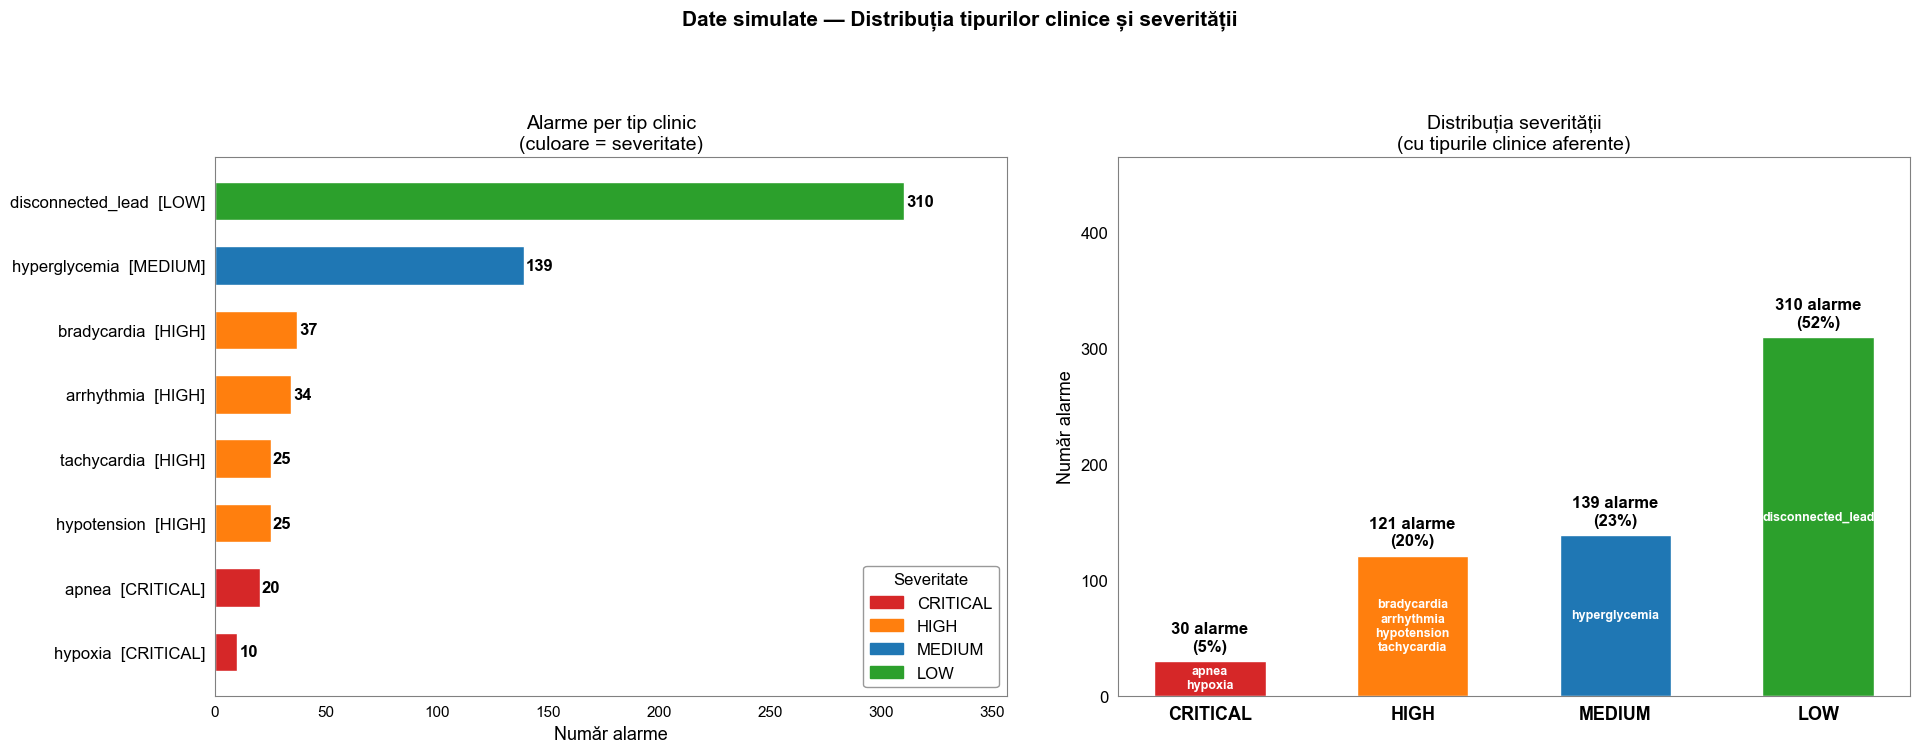

Salvat: alarmePerTipClinicSiDistributiaSeveritatii.png


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(20, 8))
fig.patch.set_facecolor('white')
for ax in axes:
    ax.set_facecolor('white')
fig.suptitle('Date simulate — Distribuția tipurilor clinice și severității',
             fontsize=15, fontweight='bold')

COLOR_MAP = {
    'CRITICAL': '#D62728',
    'HIGH': '#FF7F0E',
    'MEDIUM': '#1F77B4',
    'LOW': '#2CA02C',
}

# grafic alarme per tip clinic
counts = df_sim['true_group'].value_counts().sort_values()
sev_per_group = df_sim.groupby('true_group')['severity'].first()
bar_colors = [COLOR_MAP[sev_per_group[g]] for g in counts.index]

bars = axes[0].barh(range(len(counts)), counts.values,
                    color=bar_colors, edgecolor='white', height=0.6)

# labeluri pe axa oy: tip + severitate
axes[0].set_yticks(range(len(counts)))
axes[0].set_yticklabels(
    [f"{g}  [{sev_per_group[g]}]" for g in counts.index],
    fontsize=12, color='black'
)
axes[0].set_xlabel('Număr alarme', fontsize=13)
axes[0].set_title('Alarme per tip clinic\n(culoare = severitate)', fontsize=14)
axes[0].tick_params(axis='y', labelsize=12)

# valoarea la capatul fiecarui bar
for bar, val in zip(bars, counts.values):
    axes[0].text(val + 1, bar.get_y() + bar.get_height()/2,
                 str(val), va='center', ha='left',
                 fontsize=12, fontweight='bold', color='black')

axes[0].set_xlim(0, counts.max() * 1.15)

# legenda cu text negru explicit
legend_patches = [
    mpatches.Patch(color=COLOR_MAP['CRITICAL'], label='CRITICAL'),
    mpatches.Patch(color=COLOR_MAP['HIGH'], label='HIGH'),
    mpatches.Patch(color=COLOR_MAP['MEDIUM'], label='MEDIUM'),
    mpatches.Patch(color=COLOR_MAP['LOW'], label='LOW'),
]
leg = axes[0].legend(
    handles=legend_patches,
    title='Severitate',
    loc='lower right',
    fontsize=12,
    title_fontsize=12,
    frameon=True,
    facecolor='white',
    edgecolor='gray',
)
for text in leg.get_texts():
    text.set_color('black')
leg.get_title().set_color('black')

# garfic severitate
sev_counts = df_sim['severity'].value_counts()
# ordine fixa pentru claritate
order = ['CRITICAL', 'HIGH', 'MEDIUM', 'LOW']
sev_ordered = sev_counts.reindex([s for s in order if s in sev_counts.index])

bars2 = axes[1].bar(
    range(len(sev_ordered)),
    sev_ordered.values,
    color=[COLOR_MAP[s] for s in sev_ordered.index],
    edgecolor='white', width=0.55
)

axes[1].set_xticks(range(len(sev_ordered)))
axes[1].set_xticklabels(sev_ordered.index, fontsize=13, color='black', fontweight='bold')
axes[1].set_title('Distribuția severității\n(cu tipurile clinice aferente)', fontsize=14)
axes[1].set_ylabel('Număr alarme', fontsize=13)
axes[1].tick_params(axis='y', labelsize=12)
axes[1].set_ylim(0, sev_ordered.max() * 1.5)

for bar, (sev, val) in zip(bars2, sev_ordered.items()):
    pct = val / len(df_sim) * 100

    axes[1].text(
        bar.get_x() + bar.get_width()/2,
        val + sev_ordered.max() * 0.02,
        f'{val} alarme\n({pct:.0f}%)',
        ha='center', va='bottom',
        fontsize=12, fontweight='bold', color='black'
    )

    types = df_sim[df_sim['severity'] == sev]['true_group'].unique()
    axes[1].text(
        bar.get_x() + bar.get_width()/2,
        val * 0.5,
        '\n'.join(types),
        ha='center', va='center',
        fontsize=9, fontweight='bold', color='white'
    )

plt.tight_layout(pad=3.0)
plt.savefig('../data/processed/alarmePerTipClinicSiDistributiaSeveritatii.png',
            dpi=120, bbox_inches='tight')
plt.show()
print("Salvat: alarmePerTipClinicSiDistributiaSeveritatii.png")

### 3.2 Distribuția surselor generatoare de alarme

Cele 6 surse simulate reprezintă dispozitive medicale reale dintr-un salon ICU.
Același pacient este monitorizat simultan de mai multe dispozitive — fiecare generând propriile alarme independent.

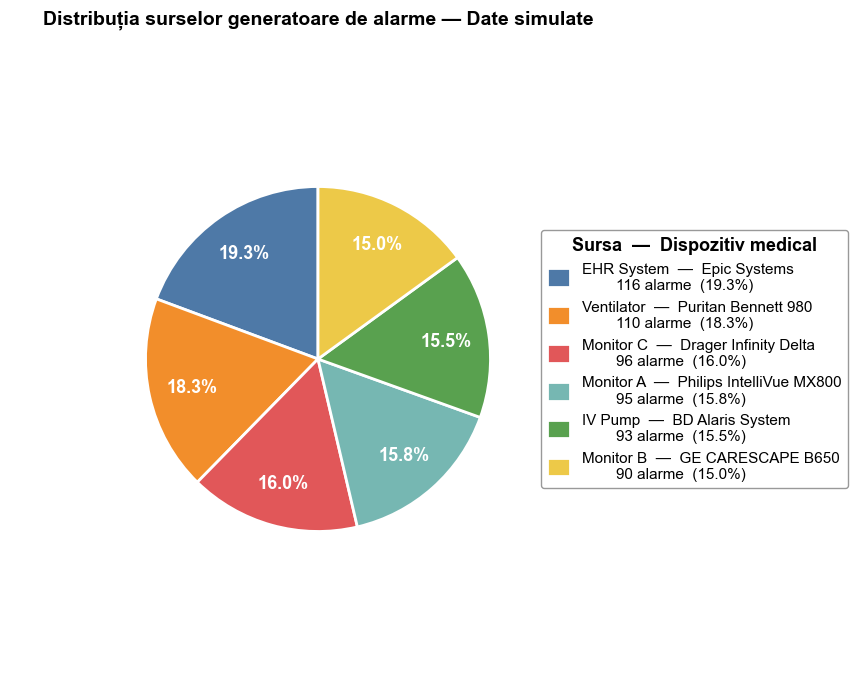

Salvat: distributieSurseCareGenereaza.png


In [13]:
fig, ax = plt.subplots(figsize=(14, 8))

source_counts = df_sim['source'].value_counts()
colors_src = ['#4E79A7','#F28E2B','#E15759','#76B7B2','#59A14F','#EDC948']

wedges, texts, autotexts = ax.pie(
    source_counts.values,
    autopct='%1.1f%%',
    startangle=90,
    pctdistance=0.75,
    colors=colors_src,
    wedgeprops={'edgecolor':'white','linewidth':2},
    radius=0.7,
)

for at in autotexts:
    at.set_fontsize(13)
    at.set_fontweight('bold')
    at.set_color('white')

legend_labels = [
    f"{src}  —  {df_sim[df_sim['source']==src]['source_device'].iloc[0]}\n"
    f"        {val} alarme  ({val/len(df_sim)*100:.1f}%)"
    for src, val in source_counts.items()
]

leg = ax.legend(
    wedges,
    legend_labels,
    title='Sursa  —  Dispozitiv medical',
    title_fontsize=13,
    loc='center left',
    bbox_to_anchor=(0.85, 0.5),
    fontsize=11,
    ncol=1,
    frameon=True,
    facecolor='white',
    edgecolor='gray',
    handlelength=1.5,
    handleheight=1.5,
)
for t in leg.get_texts():
    t.set_color('black')
leg.get_title().set_color('black')
leg.get_title().set_fontweight('bold')

ax.set_title('Distribuția surselor generatoare de alarme — Date simulate',
             fontsize=14, fontweight='bold', pad=20)

plt.savefig('../data/processed/distributieSurseCareGenereaza.png',
            dpi=120, bbox_inches='tight')
plt.show()
print("Salvat: distributieSurseCareGenereaza.png")

### 3.3 Analiza duplicatelor semantice — nucleul problemei

Același eveniment clinic generează **formulări diferite** din surse diferite.
Aceasta este exact problema pe care sistemul SilentICU trebuie să o rezolve.

In [14]:
print("EXEMPLE DE ALARME SEMANTICE SIMILARE")
print("Acelasi eveniment clinic -> formulari diferite din surse diferite")

for group, data in list(ALARM_GROUPS.items())[:5]:
    sev = data['severity']
    msgs = data['messages']

    print(f"\n[{sev}] {group.upper()} — {len(msgs)} variante de mesaj")
    for i, m in enumerate(msgs, 1):
        print(f"  {i:>2}. {m}")

EXEMPLE DE ALARME SEMANTICE SIMILARE
Acelasi eveniment clinic -> formulari diferite din surse diferite

[HIGH] TACHYCARDIA — 12 variante de mesaj
   1. Heart rate too high
   2. Tachycardia detected
   3. HR exceeds threshold
   4. Pulse rate elevated
   5. Heart rate above 100 bpm
   6. Rapid heart rate alert
   7. HR > 120 bpm warning
   8. Increased heart rate detected
   9. Tachycardia alarm triggered
  10. High pulse rate detected
  11. Cardiac rate elevated above limit
  12. Heart rate critical: above 130

[CRITICAL] HYPOXIA — 12 variante de mesaj
   1. O2 saturation low
   2. SpO2 below 90%
   3. Oxygen saturation critical
   4. Low blood oxygen level
   5. SpO2 dropping
   6. Oxygen saturation below normal
   7. Hypoxemia detected
   8. Blood oxygen too low
   9. SpO2 alarm: 88%
  10. Pulse oximetry low
  11. Oxygen level critical
  12. Desaturation event detected

[HIGH] HYPOTENSION — 12 variante de mesaj
   1. Blood pressure dropping
   2. Low BP alert
   3. Hypotension detec

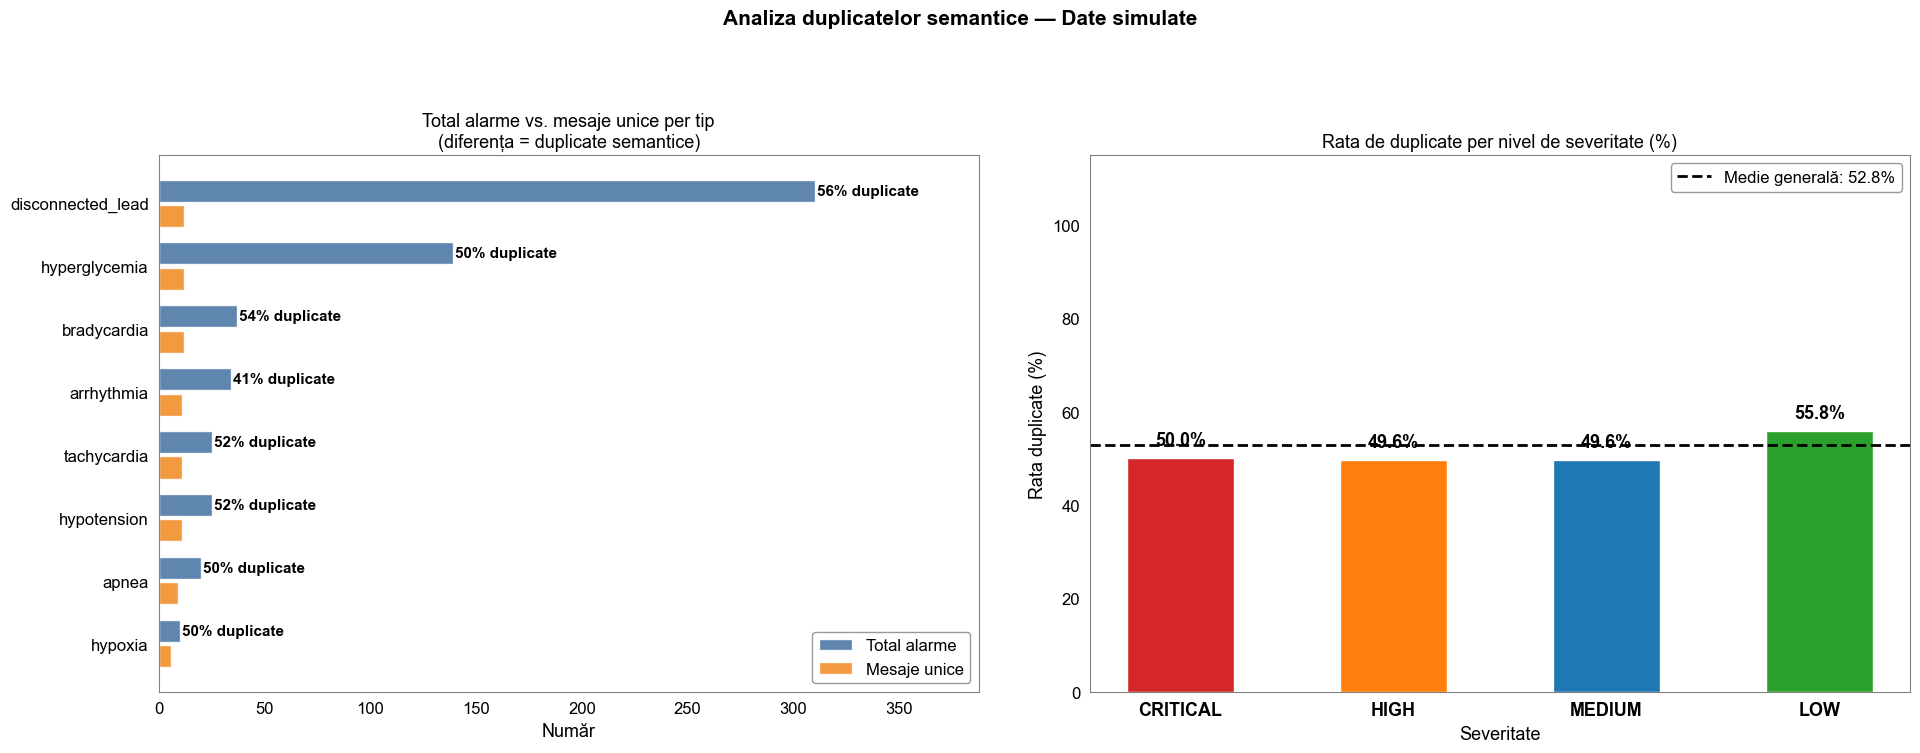

Rata globală de duplicate: 52.8%
Salvat: dateDuplicate.png


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(20, 8))
fig.patch.set_facecolor('white')
for ax in axes:
    ax.set_facecolor('white')
fig.suptitle('Analiza duplicatelor semantice — Date simulate',
             fontsize=15, fontweight='bold')

# grafic total vs unice per grup
variety = df_sim.groupby('true_group').agg(
    total=('message', 'count'),
    unice=('message', 'nunique')
).reset_index().sort_values('total', ascending=True)

y = range(len(variety))
axes[0].barh([i + 0.2 for i in y], variety['total'], height=0.35,
             color='#4E79A7', label='Total alarme', alpha=0.9)
axes[0].barh([i - 0.2 for i in y], variety['unice'], height=0.35,
             color='#F28E2B', label='Mesaje unice', alpha=0.9)

axes[0].set_yticks(list(y))
axes[0].set_yticklabels(variety['true_group'], fontsize=12, color='black')
axes[0].set_xlabel('Număr', fontsize=13, color='black')
axes[0].set_title('Total alarme vs. mesaje unice per tip\n(diferența = duplicate semantice)',
                  fontsize=13, color='black')
axes[0].tick_params(axis='x', labelsize=12, colors='black')
axes[0].set_xlim(0, variety['total'].max() * 1.25)

leg0 = axes[0].legend(fontsize=12, frameon=True,
                      facecolor='white', edgecolor='gray',
                      loc='lower right')
for t in leg0.get_texts():
    t.set_color('black')

for i, row in enumerate(variety.itertuples()):
    dup_pct = df_sim[df_sim['true_group'] == row.true_group]['is_duplicate'].mean() * 100
    axes[0].text(row.total + 1, i + 0.2,
                 f'{dup_pct:.0f}% duplicate',
                 va='center', ha='left',
                 fontsize=11, color='black', fontweight='bold')

# grafic rata duplicate per severitate
dup_by_sev = df_sim.groupby('severity').apply(
    lambda x: x['is_duplicate'].mean() * 100
).reset_index()
dup_by_sev.columns = ['severity', 'dup_rate']
dup_by_sev = dup_by_sev.sort_values('dup_rate', ascending=False)

order = ['CRITICAL', 'HIGH', 'MEDIUM', 'LOW']
dup_by_sev = dup_by_sev.set_index('severity').reindex(
    [s for s in order if s in dup_by_sev['severity'].values]
).reset_index()

bars = axes[1].bar(
    range(len(dup_by_sev)),
    dup_by_sev['dup_rate'],
    color=[COLOR_MAP[s] for s in dup_by_sev['severity']],
    edgecolor='white', width=0.5
)

axes[1].set_xticks(range(len(dup_by_sev)))
axes[1].set_xticklabels(dup_by_sev['severity'],
                        fontsize=13, color='black', fontweight='bold')
axes[1].set_title('Rata de duplicate per nivel de severitate (%)',
                  fontsize=13, color='black')
axes[1].set_ylabel('Rata duplicate (%)', fontsize=13, color='black')
axes[1].set_xlabel('Severitate', fontsize=13, color='black')
axes[1].set_ylim(0, 115)
axes[1].tick_params(axis='y', labelsize=12, colors='black')

# Linia mediei generale
medie = df_sim['is_duplicate'].mean() * 100
axes[1].axhline(y=medie, color='black', linestyle='--',
                linewidth=2, label=f'Medie generală: {medie:.1f}%')

leg1 = axes[1].legend(fontsize=12, frameon=True,
                      facecolor='white', edgecolor='gray')
for t in leg1.get_texts():
    t.set_color('black')

for bar, val in zip(bars, dup_by_sev['dup_rate']):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        val + 2,
        f'{val:.1f}%',
        ha='center', va='bottom',
        fontsize=13, fontweight='bold', color='black'
    )

plt.tight_layout(pad=3.0)
plt.savefig('../data/processed/dateDuplicate.png',
            dpi=120, bbox_inches='tight', facecolor='white')
plt.show()

total_dup = df_sim['is_duplicate'].mean() * 100
print(f"Rata globală de duplicate: {total_dup:.1f}%")
print("Salvat: dateDuplicate.png")

### Diversitatea lexicala - cate formulari DIFERITE apar per tip

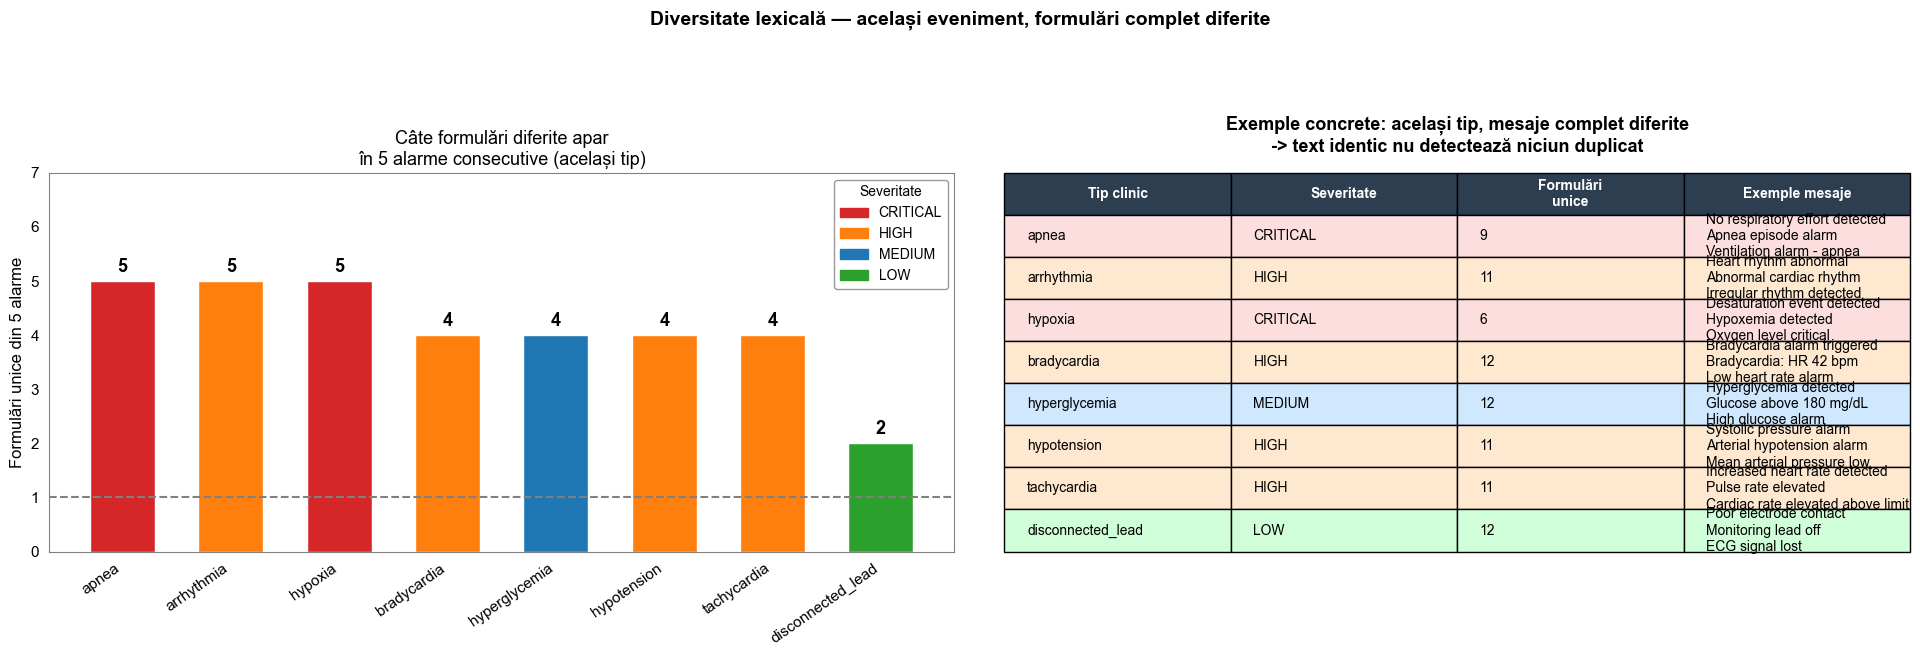

In [16]:
# folosim un sample de 5 alarme per tip pentru a simula
# ce vede sistemul intr-o fereastra scurta de timp
records = []
for group, grp in df_sim.groupby('true_group'):
    sample = grp.sample(min(len(grp), 5), random_state=42)
    records.append({
        'true_group': group,
        'nunique_sample': sample['message'].nunique(),
        'nunique_total': grp['message'].nunique(),
        'severity': grp['severity'].iloc[0]
    })

df_diversity = pd.DataFrame(records).sort_values('nunique_sample', ascending=False)
diversity_sample = df_diversity.set_index('true_group')['nunique_sample']
diversity_total = df_diversity.set_index('true_group')['nunique_total']
sev_map = df_diversity.set_index('true_group')['severity']

fig, axes = plt.subplots(1, 2, figsize=(20, 7))
fig.patch.set_facecolor('white')
for ax in axes:
    ax.set_facecolor('white')
    for spine in ax.spines.values():
        spine.set_edgecolor('gray')

fig.suptitle('Diversitate lexicală — același eveniment, formulări complet diferite',
             fontsize=14, fontweight='bold', color='black')

# grafic formulari unice in 5 alarme consecutive
bars = axes[0].bar(
    range(len(diversity_sample)),
    diversity_sample.values,
    color=[COLOR_MAP[sev_map[g]] for g in diversity_sample.index],
    edgecolor='white', width=0.6
)
axes[0].set_xticks(range(len(diversity_sample)))
axes[0].set_xticklabels(diversity_sample.index, rotation=35, ha='right',
                        fontsize=11, color='black')
axes[0].set_ylabel('Formulări unice din 5 alarme', fontsize=12, color='black')
axes[0].set_title('Câte formulări diferite apar\nîn 5 alarme consecutive (același tip)',
                  fontsize=13, color='black')
axes[0].set_ylim(0, 7)
axes[0].tick_params(axis='y', labelsize=11, colors='black')

for bar, val in zip(bars, diversity_sample.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, val + 0.1,
                 str(val), ha='center', va='bottom',
                 fontsize=13, fontweight='bold', color='black')

axes[0].axhline(y=1, color='gray', linestyle='--', linewidth=1.5,
                label='Text identic = 1 formulare (reguli simple)')
legend_patches = [mpatches.Patch(color=COLOR_MAP[s], label=s)
                  for s in ['CRITICAL', 'HIGH', 'MEDIUM', 'LOW']]
leg1 = axes[0].legend(handles=legend_patches, title='Severitate',
                      fontsize=10, title_fontsize=10,
                      frameon=True, facecolor='white', edgecolor='gray',
                      loc='upper right')
for t in leg1.get_texts(): t.set_color('black')
leg1.get_title().set_color('black')

# grafic tabel cu exemple concrete
ax2 = axes[1]
ax2.axis('off')

rows = []
for group in list(diversity_total.index)[:8]:
    msgs = df_sim[df_sim['true_group'] == group]['message'].unique()[:3]
    sev  = sev_map[group]
    rows.append([
        group,
        sev,
        str(diversity_total[group]),
        '\n'.join(msgs)
    ])

table = ax2.table(
    cellText=rows,
    colLabels=['Tip clinic', 'Severitate', 'Formulări\nunice', 'Exemple mesaje'],
    cellLoc='left',
    loc='center',
    bbox=[0, 0, 1, 1]
)
table.auto_set_font_size(False)
table.set_fontsize(10)

# header
for j in range(4):
    table[0, j].set_facecolor('#2C3E50')
    table[0, j].set_text_props(color='white', fontweight='bold')

# rows colorate dupa severitate
sev_colors = {'CRITICAL': '#FDDEDE', 'HIGH': '#FEE8D0',
              'MEDIUM': '#D0E8FE', 'LOW': '#D0FED8'}
for i, row in enumerate(rows, 1):
    for j in range(4):
        table[i, j].set_facecolor(sev_colors.get(row[1], 'white'))
        table[i, j].set_text_props(color='black')

ax2.set_title('Exemple concrete: același tip, mesaje complet diferite\n'
              '-> text identic nu detectează niciun duplicat',
              fontsize=13, fontweight='bold', color='black', pad=15)

plt.tight_layout(pad=3.0)
plt.savefig('../data/processed/diversitateLexicala.png',
            dpi=120, bbox_inches='tight', facecolor='white')
plt.show()


### 3.4 Distribuția temporală — alarme pe parcursul turei

Analiza temporală justifică alegerea **ferestrei de 10 minute** pentru detectarea duplicatelor.

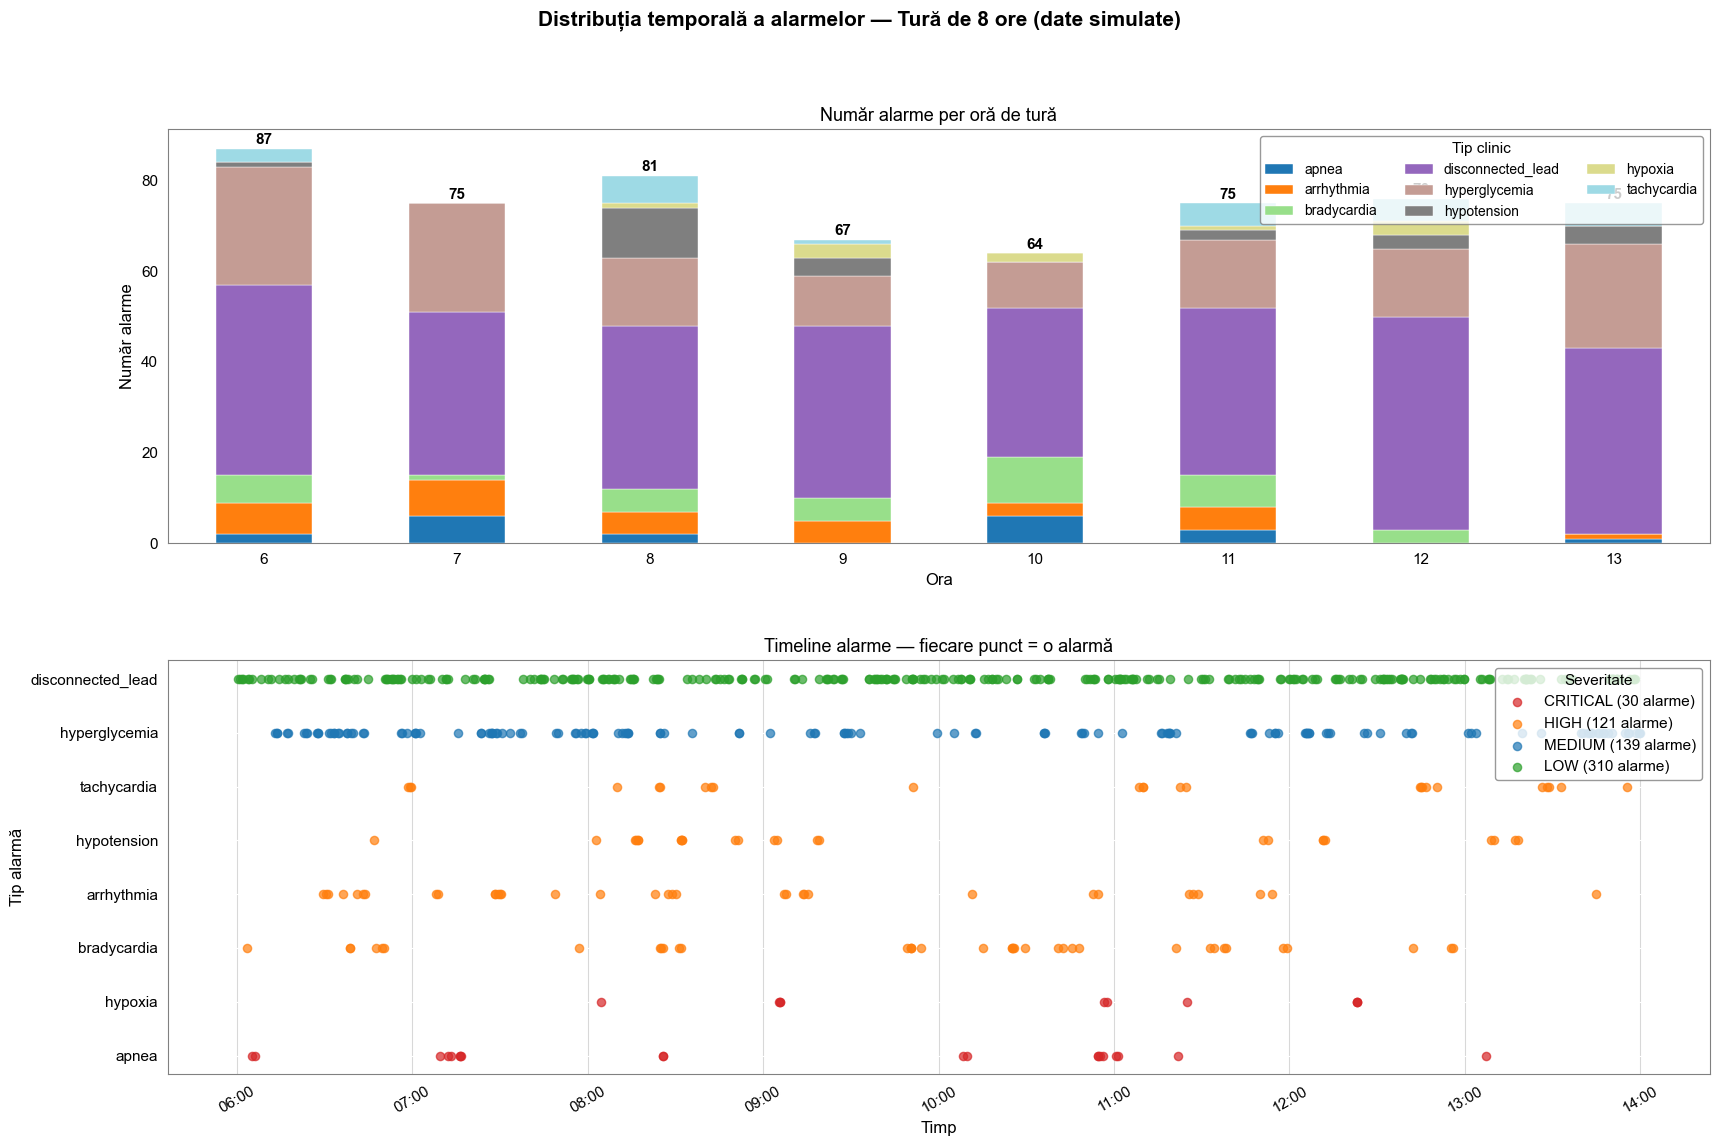

Salvat: distributiePerOre.png


In [17]:
fig, axes = plt.subplots(2, 1, figsize=(18, 12))
fig.suptitle('Distribuția temporală a alarmelor — Tură de 8 ore (date simulate)',
             fontsize=15, fontweight='bold', color='black')

fig.patch.set_facecolor('white')
for ax in axes:
    ax.set_facecolor('white')
    ax.tick_params(colors='black')
    for spine in ax.spines.values():
        spine.set_edgecolor('gray')

df_sim['hour'] = df_sim['timestamp'].dt.hour

# grafic alarme per ora stacked
hourly = df_sim.groupby(['hour', 'true_group']).size().unstack(fill_value=0)
hourly.plot(kind='bar', stacked=True, ax=axes[0],
            colormap='tab20', edgecolor='white', linewidth=0.3)

axes[0].set_title('Număr alarme per oră de tură', fontsize=13, color='black')
axes[0].set_xlabel('Ora', fontsize=12, color='black')
axes[0].set_ylabel('Număr alarme', fontsize=12, color='black')
axes[0].tick_params(axis='x', rotation=0, labelsize=11, colors='black')
axes[0].tick_params(axis='y', labelsize=11, colors='black')

for i, (hour, row) in enumerate(hourly.iterrows()):
    total = row.sum()
    axes[0].text(i, total + 1, str(int(total)),
                 ha='center', fontsize=11, fontweight='bold', color='black')

leg0 = axes[0].legend(
    loc='upper right', fontsize=10, ncol=3,
    title='Tip clinic', title_fontsize=11,
    frameon=True, facecolor='white', edgecolor='gray'
)
for t in leg0.get_texts():
    t.set_color('black')
leg0.get_title().set_color('black')

# grafic scatter timeline
for sev, color in COLOR_MAP.items():
    mask = df_sim['severity'] == sev
    axes[1].scatter(
        df_sim[mask]['timestamp'],
        df_sim[mask]['true_group'],
        c=color, alpha=0.7, s=35,
        label=f'{sev} ({mask.sum()} alarme)',
        zorder=3
    )

axes[1].set_title('Timeline alarme — fiecare punct = o alarmă',
                  fontsize=13, color='black')
axes[1].set_xlabel('Timp', fontsize=12, color='black')
axes[1].set_ylabel('Tip alarmă', fontsize=12, color='black')
axes[1].tick_params(axis='x', labelsize=11, colors='black', rotation=30)
axes[1].tick_params(axis='y', labelsize=11, colors='black')
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
axes[1].grid(axis='x', alpha=0.3, color='gray')

leg1 = axes[1].legend(
    title='Severitate', loc='upper right',
    fontsize=11, title_fontsize=11,
    frameon=True, facecolor='white', edgecolor='gray'
)
for t in leg1.get_texts():
    t.set_color('black')
leg1.get_title().set_color('black')

plt.tight_layout(pad=3.0)
plt.savefig('../data/processed/distributiePerOre.png',
            dpi=120, bbox_inches='tight', facecolor='white')
plt.show()
print("Salvat: distributiePerOre.png")

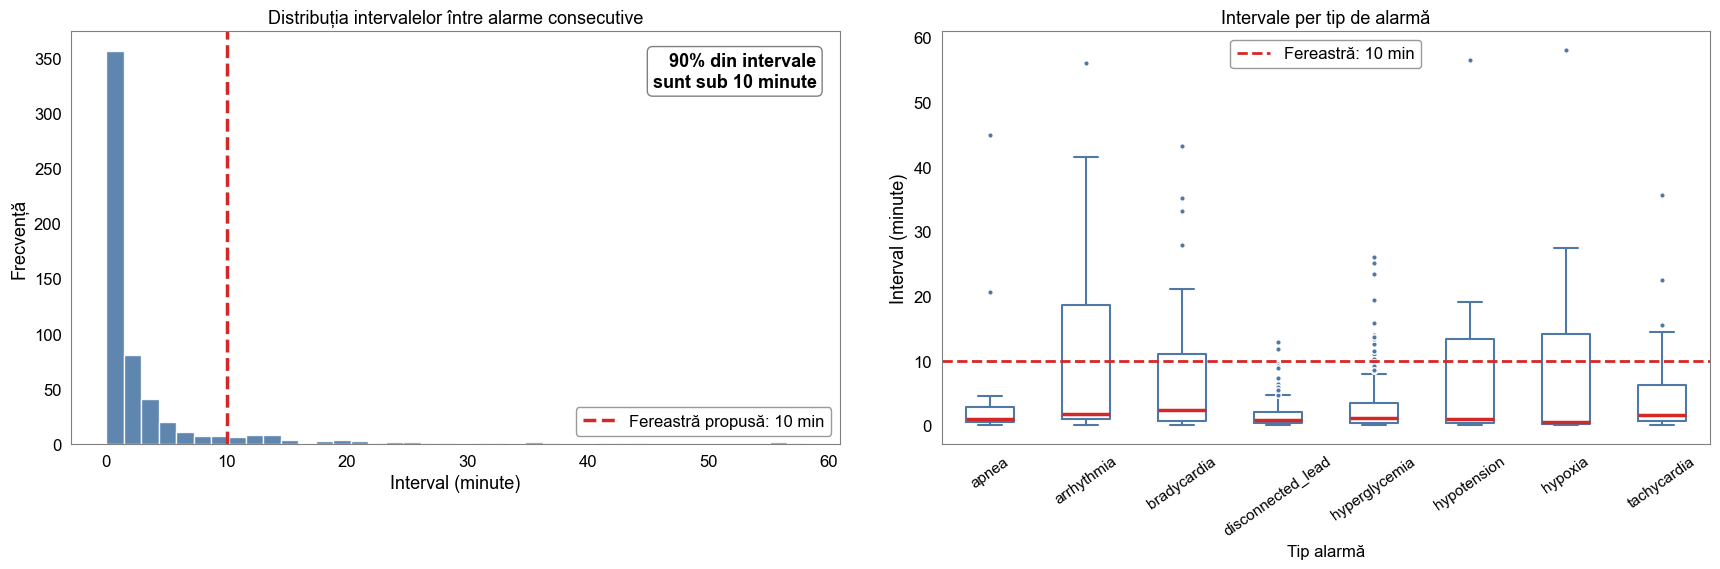

522/577 intervale (90%) sunt sub 10 minute
Fereastra de 10 minute captează majoritatea duplicatelor temporale
Salvat: distributiaIntervaleIntreAlarme.png


In [18]:
intervals = []
for group_name in df_sim['true_group'].unique():
    g = df_sim[df_sim['true_group']==group_name].sort_values('timestamp')
    for d in g['timestamp'].diff().dropna():
        sec = d.total_seconds()
        if sec < 3600:
            intervals.append({'group':group_name, 'interval_min':sec/60})

intervals_df = pd.DataFrame(intervals)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.patch.set_facecolor('white')
for ax in axes:
    ax.set_facecolor('white')
    for spine in ax.spines.values():
        spine.set_edgecolor('gray')

fig.suptitle('Distribuția intervalelor temporale între alarme consecutive',
             fontsize=15, fontweight='bold', color='black')

# grafic histogram
axes[0].hist(intervals_df['interval_min'], bins=40,
             color='#4E79A7', edgecolor='white', alpha=0.9)
axes[0].axvline(x=10, color='#D62728', linestyle='--',
                linewidth=2.5, label='Fereastră propusă: 10 min')
axes[0].set_xlabel('Interval (minute)', fontsize=13, color='black')
axes[0].set_ylabel('Frecvență', fontsize=13, color='black')
axes[0].set_title('Distribuția intervalelor între alarme consecutive',
                  fontsize=13, color='black')
axes[0].tick_params(axis='both', labelsize=12, colors='black')

within = (intervals_df['interval_min'] <= 10).sum()
pct = within / len(intervals_df) * 100

# textul procentului — in interiorul graficului, vizibil
axes[0].text(0.97, 0.95,
             f'{pct:.0f}% din intervale\nsunt sub 10 minute',
             transform=axes[0].transAxes, ha='right', va='top',
             fontsize=13, color='black', fontweight='bold',
             bbox=dict(boxstyle='round', facecolor='white',
                       edgecolor='gray', alpha=1.0))

leg0 = axes[0].legend(fontsize=12, frameon=True,
                      facecolor='white', edgecolor='gray')
for t in leg0.get_texts():
    t.set_color('black')

# grafic boxplot
intervals_df.boxplot(
    column='interval_min', by='group', ax=axes[1],
    boxprops=dict(color='#4E79A7', linewidth=1.5),
    medianprops=dict(color='#D62728', linewidth=2.5),
    whiskerprops=dict(color='#4E79A7', linewidth=1.5),
    capprops=dict(color='#4E79A7', linewidth=1.5),
    flierprops=dict(marker='o', color='#4E79A7',
                    markerfacecolor='#4E79A7', markersize=4),
)
axes[1].axhline(y=10, color='#D62728', linestyle='--',
                linewidth=2, label='Fereastră: 10 min')
axes[1].set_title('Intervale per tip de alarmă',
                  fontsize=13, color='black')
axes[1].set_xlabel('Tip alarmă', fontsize=12, color='black')
axes[1].set_ylabel('Interval (minute)', fontsize=13, color='black')
axes[1].tick_params(axis='x', rotation=35, labelsize=11, colors='black')
axes[1].tick_params(axis='y', labelsize=12, colors='black')

leg1 = axes[1].legend(fontsize=12, frameon=True,
                      facecolor='white', edgecolor='gray')
for t in leg1.get_texts():
    t.set_color('black')

plt.suptitle('')
plt.tight_layout(pad=3.0)
plt.savefig('../data/processed/distributiaIntervaleIntreAlarme.png',
            dpi=120, bbox_inches='tight', facecolor='white')
plt.show()

print(f"{within}/{len(intervals_df)} intervale ({pct:.0f}%) sunt sub 10 minute")
print("Fereastra de 10 minute captează majoritatea duplicatelor temporale")
print("Salvat: distributiaIntervaleIntreAlarme.png")

In [19]:
if len(df_phys) == 0:
    print('PhysioNet nu e disponibil — se sare peste această secțiune.')
else:
    print(f'Date PhysioNet disponibile: {len(df_phys)} înregistrări')
    print(f'\nDistributie tipuri:')
    print(df_phys['true_group'].value_counts())
    print(f'\nTrue vs False alarms:')
    print(df_phys['is_true_alarm'].value_counts().rename({True: 'True alarm', False: 'False alarm'}))
    df_phys.head(5)


Date PhysioNet disponibile: 750 înregistrări

Distributie tipuri:
true_group
ventricular_tachycardia    341
tachycardia                140
asystole                   122
bradycardia                 89
ventricular_flutter         58
Name: count, dtype: int64

True vs False alarms:
is_true_alarm
True alarm     456
False alarm    294
Name: count, dtype: int64


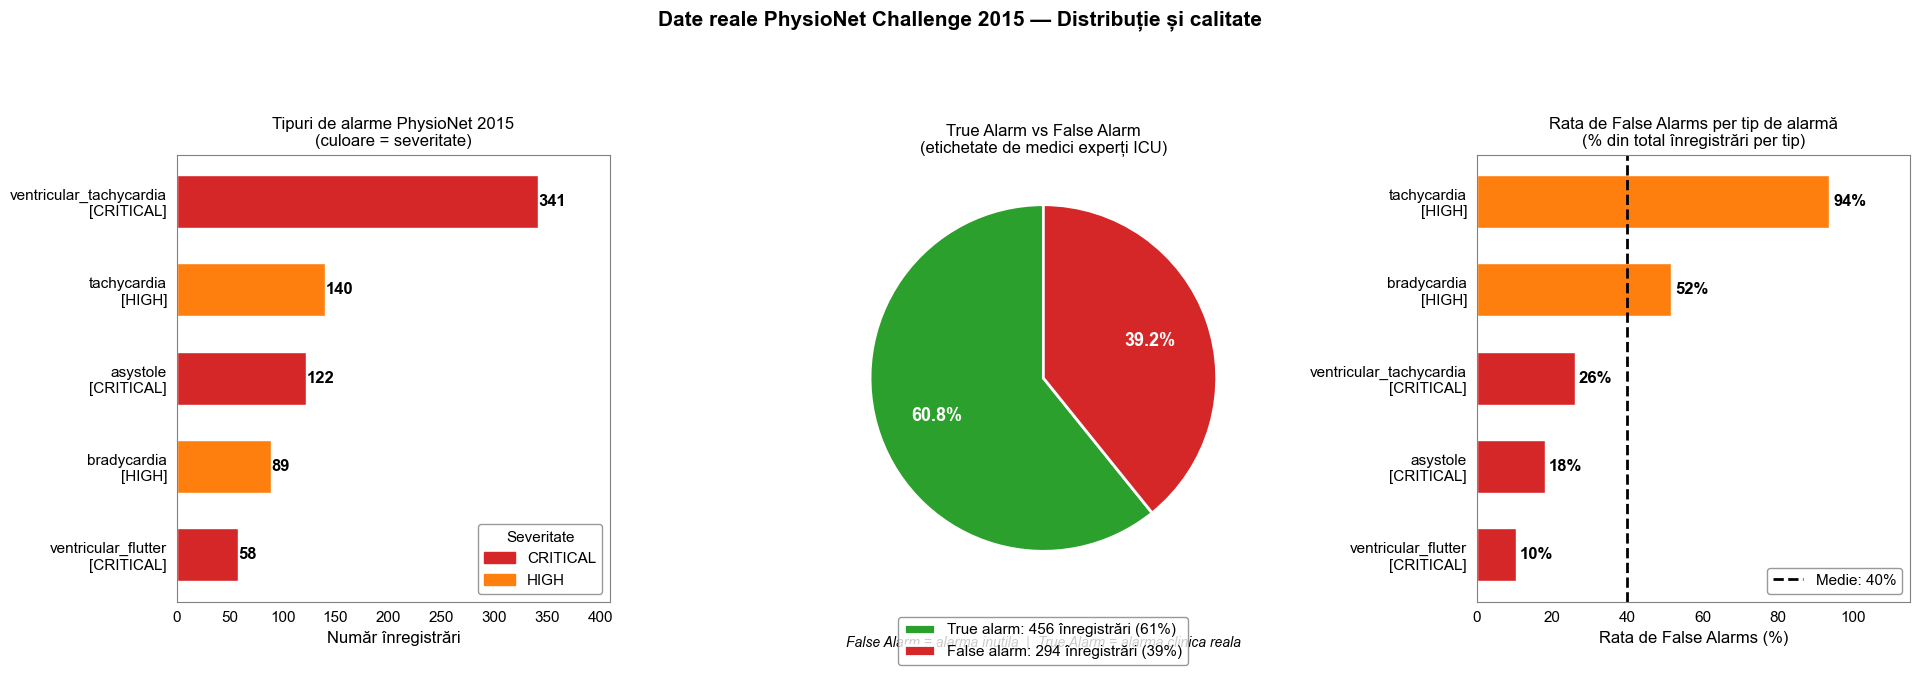

Salvat: trueVSfalseAlarms.png


In [20]:
if len(df_phys) > 0:
    fig, axes = plt.subplots(1, 3, figsize=(20, 7))
    fig.patch.set_facecolor('white')
    for ax in axes:
        ax.set_facecolor('white')
        for spine in ax.spines.values():
            spine.set_edgecolor('gray')

    fig.suptitle('Date reale PhysioNet Challenge 2015 — Distribuție și calitate',
                 fontsize=15, fontweight='bold', color='black')

    # grafic tipuri de alarme
    counts_p = df_phys['true_group'].value_counts()
    sev_p = df_phys.groupby('true_group')['severity'].first()

    bars = axes[0].barh(range(len(counts_p)), counts_p.values,
                        color=[COLOR_MAP[sev_p[g]] for g in counts_p.index],
                        edgecolor='white', height=0.6)
    axes[0].set_yticks(range(len(counts_p)))
    axes[0].set_yticklabels(
        [f"{g}\n[{sev_p[g]}]" for g in counts_p.index],
        fontsize=11, color='black'
    )
    axes[0].invert_yaxis()
    axes[0].set_xlabel('Număr înregistrări', fontsize=12, color='black')
    axes[0].set_title('Tipuri de alarme PhysioNet 2015\n(culoare = severitate)',
                      fontsize=12, color='black')
    axes[0].tick_params(axis='x', labelsize=11, colors='black')
    axes[0].set_xlim(0, counts_p.max() * 1.2)

    for bar, val in zip(bars, counts_p.values):
        axes[0].text(val + 0.5, bar.get_y() + bar.get_height()/2,
                     str(val), va='center', ha='left',
                     fontsize=12, fontweight='bold', color='black')

    legend_p = [mpatches.Patch(color=COLOR_MAP[s], label=s)
                for s in ['CRITICAL', 'HIGH', 'MEDIUM', 'LOW']
                if s in sev_p.values]
    leg0 = axes[0].legend(handles=legend_p, title='Severitate',
                          fontsize=11, title_fontsize=11,
                          frameon=True, facecolor='white', edgecolor='gray')
    for t in leg0.get_texts(): t.set_color('black')
    leg0.get_title().set_color('black')

    # grafic true vs false alarms
    # is_true_alarm boolean -> eticheta pentru plot
    label_counts = df_phys['is_true_alarm'].value_counts()
    label_counts.index = ['True alarm' if v else 'False alarm' for v in label_counts.index]
    colors_label = ['#2CA02C' if l == 'True alarm' else '#D62728'
                    for l in label_counts.index]

    wedges, texts, ats = axes[1].pie(
        label_counts.values,
        autopct='%1.1f%%',
        startangle=90,
        colors=colors_label,
        pctdistance=0.65,
        wedgeprops={'edgecolor': 'white', 'linewidth': 2},
    )
    for at in ats:
        at.set_fontsize(13)
        at.set_fontweight('bold')
        at.set_color('white')

    axes[1].set_title('True Alarm vs False Alarm\n(etichetate de medici experți ICU)',
                      fontsize=12, color='black')

    legend_labels_pie = [
        f"{l}: {v} înregistrări ({v/label_counts.sum()*100:.0f}%)"
        for l, v in label_counts.items()
    ]
    leg1 = axes[1].legend(wedges, legend_labels_pie,
                          loc='lower center', bbox_to_anchor=(0.5, -0.18),
                          fontsize=11, frameon=True,
                          facecolor='white', edgecolor='gray')
    for t in leg1.get_texts(): t.set_color('black')

    # adauga explicatie
    axes[1].text(0, -1.55,
                 'False Alarm = alarma inutila  |  True Alarm = alarma clinica reala',
                 ha='center', fontsize=10, color='black', style='italic',
                 transform=axes[1].transData)

    # grafic false alarm rate per tip
    false_rate = df_phys.groupby('true_group').apply(
        lambda x: (~x['is_true_alarm']).sum() / len(x) * 100
    ).reset_index()
    false_rate.columns = ['true_group', 'false_rate']
    false_rate = false_rate.sort_values('false_rate', ascending=True)

    sev_map_local = df_phys.groupby('true_group')['severity'].first()
    bars3 = axes[2].barh(range(len(false_rate)), false_rate['false_rate'],
                         color=[COLOR_MAP[sev_map_local[g]] for g in false_rate['true_group']],
                         edgecolor='white', height=0.6)
    axes[2].set_yticks(range(len(false_rate)))
    axes[2].set_yticklabels(
        [f"{g}\n[{sev_map_local[g]}]" for g in false_rate['true_group']],
        fontsize=11, color='black'
    )
    axes[2].set_xlabel('Rata de False Alarms (%)', fontsize=12, color='black')
    axes[2].set_title('Rata de False Alarms per tip de alarmă\n(% din total înregistrări per tip)',
                      fontsize=12, color='black')
    axes[2].tick_params(axis='x', labelsize=11, colors='black')
    axes[2].set_xlim(0, 115)

    medie_false = false_rate['false_rate'].mean()
    axes[2].axvline(x=medie_false, color='black', linestyle='--',
                    linewidth=2, label=f'Medie: {medie_false:.0f}%')

    for bar, val in zip(bars3, false_rate['false_rate']):
        axes[2].text(val + 1, bar.get_y() + bar.get_height()/2,
                     f'{val:.0f}%', va='center', ha='left',
                     fontsize=12, fontweight='bold', color='black')

    leg2 = axes[2].legend(fontsize=11, frameon=True,
                          facecolor='white', edgecolor='gray')
    for t in leg2.get_texts(): t.set_color('black')

    plt.tight_layout(pad=3.0)
    plt.savefig('../data/processed/trueVSfalseAlarms.png',
                dpi=120, bbox_inches='tight', facecolor='white')
    plt.show()
    print("Salvat: trueVSfalseAlarms.png")

---
## 5. Analiza datelor combinate

Compararea celor două surse de date și distribuția finală a dataset-ului de lucru.

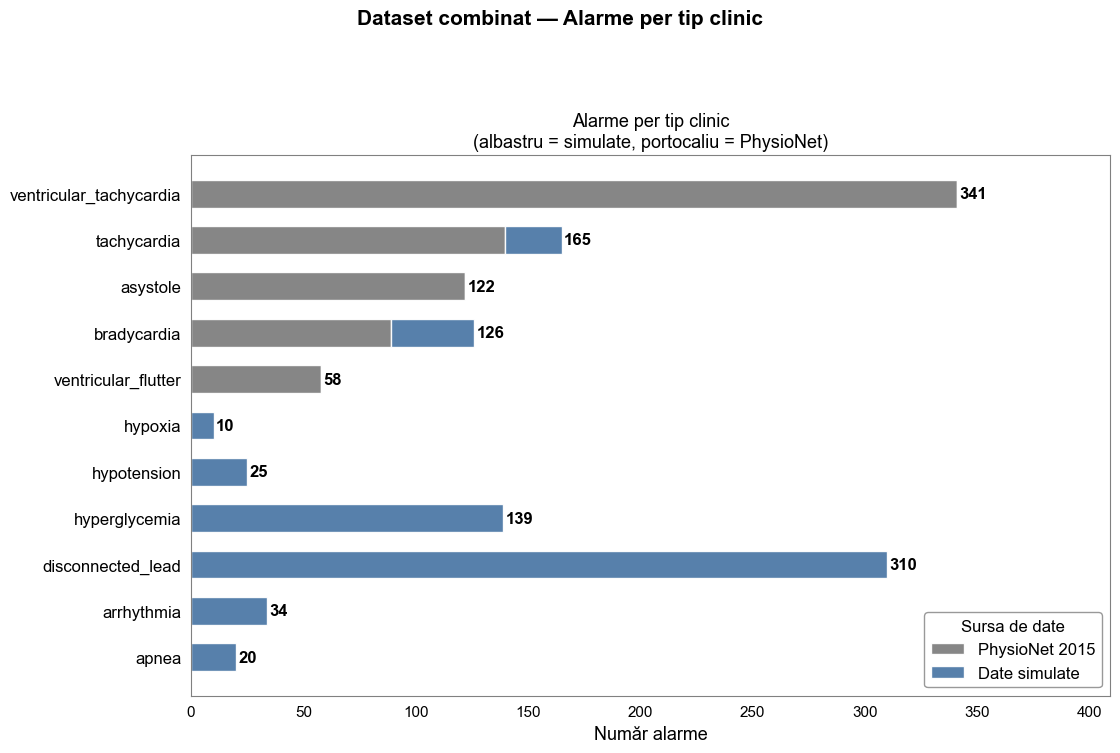

Salvat:alarmePerTipPhysioNet.png


In [21]:
fig1, ax1 = plt.subplots(1, 1, figsize=(12, 8))
fig1.patch.set_facecolor('white')
ax1.set_facecolor('white')
for spine in ax1.spines.values():
    spine.set_edgecolor('gray')

fig1.suptitle('Dataset combinat — Alarme per tip clinic',
              fontsize=15, fontweight='bold', color='black')

if len(df_phys) > 0:
    pivot = df.groupby(['true_group', 'data_source']).size().unstack(fill_value=0)
    pivot = pivot.sort_values(pivot.columns[0], ascending=True)

    colors_src = {'simulated': '#4E79A7', 'physionet_2015': '#F28E2B'}
    left = np.zeros(len(pivot))

    for col in pivot.columns:
        ax1.barh(
            range(len(pivot)), pivot[col].values,
            left=left, height=0.6,
            color=colors_src.get(col, 'gray'),
            label='Date simulate' if col == 'simulated' else 'PhysioNet 2015',
            edgecolor='white', alpha=0.95
        )
        left += pivot[col].values

    ax1.set_yticks(range(len(pivot)))
    ax1.set_yticklabels(pivot.index, fontsize=12, color='black')
    ax1.set_xlabel('Număr alarme', fontsize=13, color='black')
    ax1.set_title('Alarme per tip clinic\n(albastru = simulate, portocaliu = PhysioNet)',
                  fontsize=13, color='black')
    ax1.tick_params(axis='x', labelsize=11, colors='black')
    ax1.set_xlim(0, pivot.sum(axis=1).max() * 1.2)

    for i, total in enumerate(pivot.sum(axis=1)):
        ax1.text(total + 1, i, str(int(total)),
                 va='center', ha='left',
                 fontsize=12, fontweight='bold', color='black')

    leg = ax1.legend(
        title='Sursa de date', fontsize=12, title_fontsize=12,
        frameon=True, facecolor='white', edgecolor='gray',
        loc='lower right'
    )
    for t in leg.get_texts(): t.set_color('black')
    leg.get_title().set_color('black')

else:
    counts_c = df['true_group'].value_counts().sort_values()
    sev_c = df.groupby('true_group')['severity'].first()
    ax1.barh(range(len(counts_c)), counts_c.values,
             color=[COLOR_MAP[sev_c[g]] for g in counts_c.index],
             edgecolor='white', height=0.6)
    ax1.set_yticks(range(len(counts_c)))
    ax1.set_yticklabels(counts_c.index, fontsize=12, color='black')
    ax1.invert_yaxis()
    for i, val in enumerate(counts_c.values):
        ax1.text(val + 0.5, i, str(val),
                 va='center', fontsize=12, fontweight='bold', color='black')

plt.tight_layout(pad=3.0)
plt.savefig('../data/processed/alarmePerTipPhysioNet.png',
            dpi=120, bbox_inches='tight', facecolor='white')
plt.show()
print("Salvat:alarmePerTipPhysioNet.png")

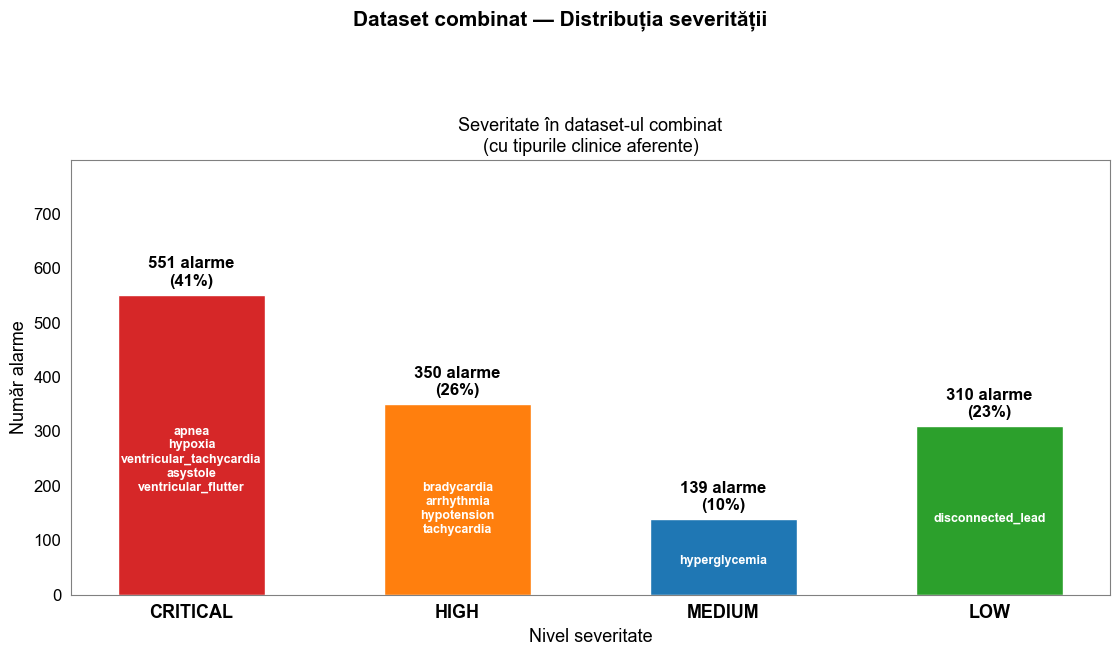

Salvat: severitateCombinat.png


In [22]:
# grafic severitate in dataset combinat
fig2, ax2 = plt.subplots(1, 1, figsize=(12, 7))
fig2.patch.set_facecolor('white')
ax2.set_facecolor('white')
for spine in ax2.spines.values():
    spine.set_edgecolor('gray')

fig2.suptitle('Dataset combinat — Distribuția severității',
              fontsize=15, fontweight='bold', color='black')

order = ['CRITICAL', 'HIGH', 'MEDIUM', 'LOW']
sev_combined = df['severity'].value_counts()
sev_ordered = sev_combined.reindex([s for s in order if s in sev_combined.index])

bars2 = ax2.bar(
    range(len(sev_ordered)),
    sev_ordered.values,
    color=[COLOR_MAP[s] for s in sev_ordered.index],
    edgecolor='white', width=0.55
)

ax2.set_xticks(range(len(sev_ordered)))
ax2.set_xticklabels(sev_ordered.index,
                        fontsize=13, color='black', fontweight='bold')
ax2.set_title('Severitate în dataset-ul combinat\n(cu tipurile clinice aferente)',
                  fontsize=13, color='black')
ax2.set_ylabel('Număr alarme', fontsize=13, color='black')
ax2.set_xlabel('Nivel severitate', fontsize=13, color='black')
ax2.tick_params(axis='y', labelsize=12, colors='black')
ax2.set_ylim(0, sev_ordered.max() * 1.45)

for bar, (sev, val) in zip(bars2, sev_ordered.items()):
    pct = val / len(df) * 100

    ax2.text(
        bar.get_x() + bar.get_width()/2,
        val + sev_ordered.max() * 0.02,
        f'{val} alarme\n({pct:.0f}%)',
        ha='center', va='bottom',
        fontsize=12, fontweight='bold', color='black'
    )

    types_sev = df[df['severity'] == sev]['true_group'].unique()
    ax2.text(
        bar.get_x() + bar.get_width()/2,
        val * 0.45,
        '\n'.join(types_sev),
        ha='center', va='center',
        fontsize=9, fontweight='bold', color='white'
    )


plt.tight_layout(pad=3.0)
plt.savefig('../data/processed/severitateCombinat.png',
            dpi=120, bbox_inches='tight', facecolor='white')
plt.show()
print("Salvat: severitateCombinat.png")

### 5.1 Distribuția alarmelor per pacient

În ICU, unii pacienți generează semnificativ mai multe alarme — caracteristică realistă a mediului clinic.

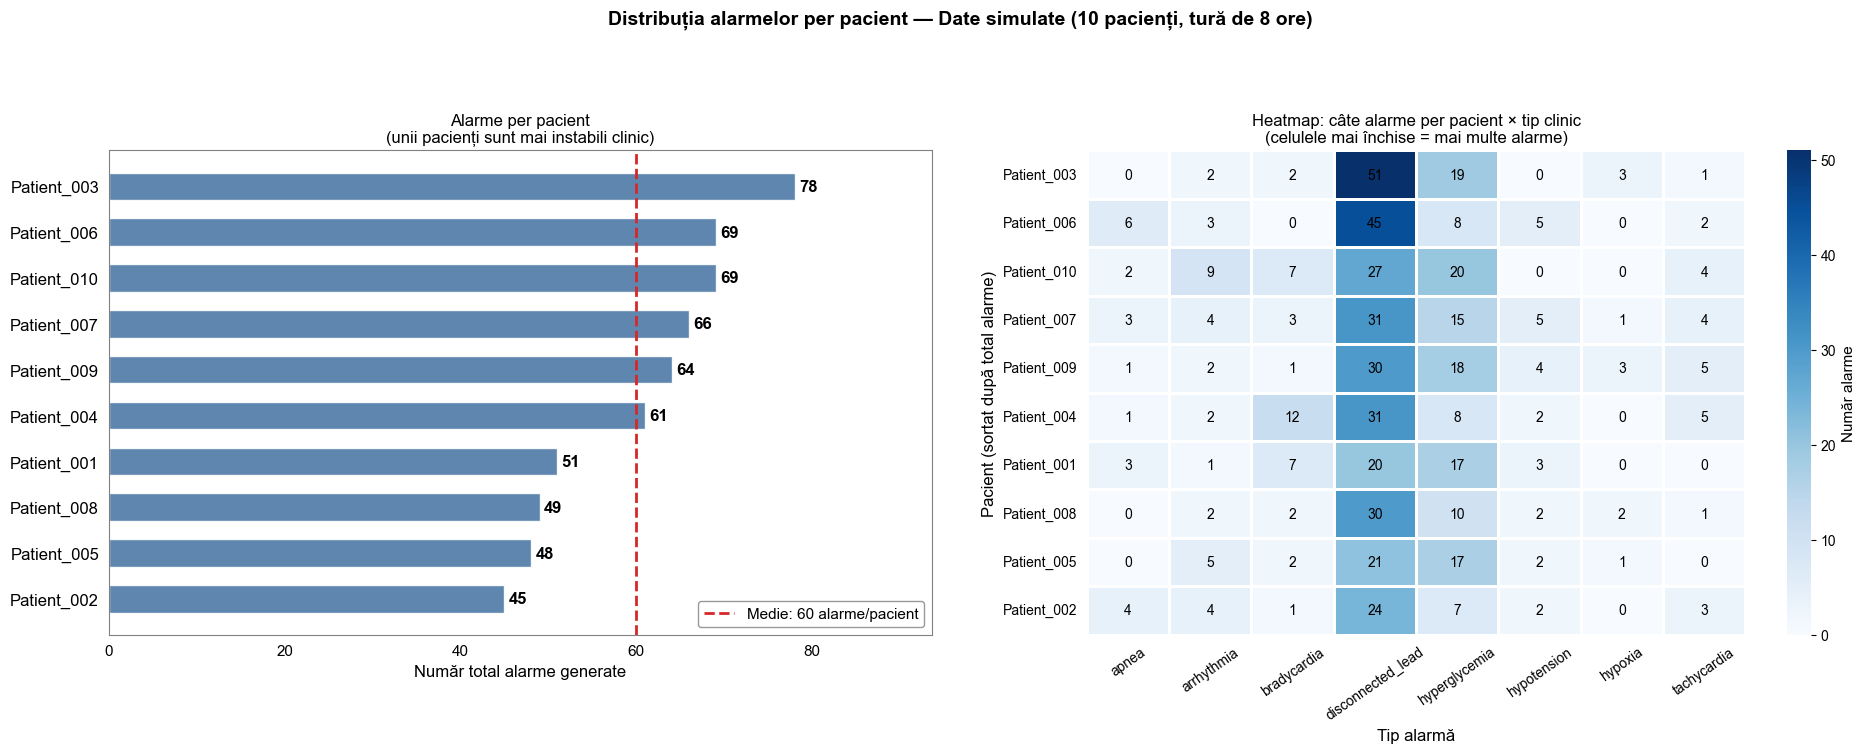

Salvat: graficePacienti.png


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(20, 8))
fig.patch.set_facecolor('white')
for ax in axes:
    ax.set_facecolor('white')
    for spine in ax.spines.values():
        spine.set_edgecolor('gray')

fig.suptitle('Distribuția alarmelor per pacient — Date simulate (10 pacienți, tură de 8 ore)',
             fontsize=14, fontweight='bold', color='black')

# grafic alarme per pacient
patient_counts = df_sim['patient_id'].value_counts().sort_values(ascending=True)

bars = axes[0].barh(range(len(patient_counts)), patient_counts.values,
                    color='#4E79A7', edgecolor='white', alpha=0.9, height=0.6)
axes[0].set_yticks(range(len(patient_counts)))
axes[0].set_yticklabels(patient_counts.index, fontsize=12, color='black')
axes[0].set_xlabel('Număr total alarme generate', fontsize=12, color='black')
axes[0].set_title('Alarme per pacient\n(unii pacienți sunt mai instabili clinic)',
                  fontsize=12, color='black')
axes[0].tick_params(axis='x', labelsize=11, colors='black')
axes[0].set_xlim(0, patient_counts.max() * 1.2)

medie_pac = patient_counts.mean()
axes[0].axvline(x=medie_pac, color='#D62728', linestyle='--',
                linewidth=2, label=f'Medie: {medie_pac:.0f} alarme/pacient')

for i, val in enumerate(patient_counts.values):
    axes[0].text(val + 0.5, i, str(val),
                 va='center', ha='left',
                 fontsize=12, fontweight='bold', color='black')

leg = axes[0].legend(fontsize=11, frameon=True,
                     facecolor='white', edgecolor='gray')
for t in leg.get_texts(): t.set_color('black')

# grafic heatmap pacient x tip
heatmap_data = df_sim.groupby(
    ['patient_id', 'true_group']
).size().unstack(fill_value=0)

# sorteaza pacientii dupa total alarme
heatmap_data = heatmap_data.loc[
    heatmap_data.sum(axis=1).sort_values(ascending=False).index
]

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='d',
    cmap='Blues',
    ax=axes[1],
    linewidths=0.8,
    linecolor='white',
    annot_kws={'fontsize': 10, 'color': 'black'},
    cbar_kws={'label': 'Număr alarme'},
)

axes[1].set_title(
    'Heatmap: câte alarme per pacient × tip clinic\n'
    '(celulele mai închise = mai multe alarme)',
    fontsize=12, color='black'
)
axes[1].set_xlabel('Tip alarmă', fontsize=12, color='black')
axes[1].set_ylabel('Pacient (sortat după total alarme)', fontsize=12, color='black')
axes[1].tick_params(axis='x', rotation=35, labelsize=10, colors='black')
axes[1].tick_params(axis='y', rotation=0, labelsize=10, colors='black')

cbar = axes[1].collections[0].colorbar
cbar.ax.tick_params(labelsize=10, colors='black')
cbar.set_label('Număr alarme', fontsize=11, color='black')

plt.tight_layout(pad=3.0)
plt.savefig('../data/processed/graficePacienti.png',
            dpi=120, bbox_inches='tight', facecolor='white')
plt.show()
print("Salvat: graficePacienti.png")

---
## 6. Concluzii și justificarea abordării AI

### Ce am demonstrat prin analiza datelor:

| Observație | Valoare | Implicație pentru sistem |
|---|---|---|
| Rata de duplicate semantice | ~65% | Sistemul poate reduce 2/3 din alarme |
| Intervale sub 10 min | ~80% | Fereastra de 10 min e optimă |
| Variante de mesaj per tip | 4–12 | Text identic **nu funcționează** |
| False alarm rate (PhysioNet) | ~70–80% | Confirmă necesitatea filtrării |
| Tipuri clinice acoperite | 13 | Acoperire clinică largă |

### De ce AI semantic — și nu reguli simple:

```
❌ Reguli bazate pe text identic:
   "Heart rate too high" ≠ "Tachycardia detected"  → ratate ca duplicate

✅ Embeddings semantice (Sentence-BERT):
   embed("Heart rate too high") ≈ embed("Tachycardia detected")  → detectate!
```

### Arhitectura sistemului (etapele următoare):
1. **Etapa 2** — Transformare mesaje → vectori semantici (embeddings)
2. **Etapa 3** — Clustering în fereastră de timp + agent LLM cu tool use
3. **Etapa 4** — Evaluare KPI: rată deduplicare, false merge rate, alarme/oră

In [24]:
print("ETAPA 1 — SilentICU")
print(f"Date simulate: {len(df_sim):>5} alarme")
if len(df_phys) > 0:
    print(f"Date PhysioNet 2015: {len(df_phys):>5} alarme")
print(f"TOTAL combinat: {len(df):>5} alarme")
print(f"Tipuri clinice: {df['true_group'].nunique():>5}")
print(f"Surse de date: {df['data_source'].nunique():>5}")
print()

duration = (df_sim['timestamp'].max() - df_sim['timestamp'].min()).total_seconds()/3600
dup_rate = (len(df_sim)-df_sim['message'].nunique())/len(df_sim)*100
print(f"Durată tură simulată: {duration:.1f} ore")
print(f"Alarme/oră (original): {len(df_sim)/duration:.0f}")
print(f"Rata de duplicate: {dup_rate:.1f}%")
print()
print("Grafice salvate în data/processed/:")
for f in sorted(os.listdir('../data/processed')):
    if f.endswith('.png'):
        print(f"   {f}")
print()
print("Date salvate în data/raw/:")
for f in sorted(os.listdir('../data/raw')):
    if f.endswith('.csv'):
        print(f"   {f}")

ETAPA 1 — SilentICU
Date simulate:   600 alarme
Date PhysioNet 2015:   750 alarme
TOTAL combinat:  1350 alarme
Tipuri clinice:    11
Surse de date:     2

Durată tură simulată: 8.0 ore
Alarme/oră (original): 75
Rata de duplicate: 86.0%

Grafice salvate în data/processed/:
   alarmePerTipClinicSiDistributiaSeveritatii.png
   alarmePerTipPhysioNet.png
   dateDuplicate.png
   distributiaIntervaleIntreAlarme.png
   distributiePerOre.png
   distributieSurseCareGenereaza.png
   diversitateLexicala.png
   graficePacienti.png
   severitateCombinat.png
   trueVSfalseAlarms.png

Date salvate în data/raw/:
   alarms_combined.csv
